# **From Incremental Lift to Long-Term Customer Value**

## 1. Business Context

In my previous company, one of our core solutions was to measure the **incremental lift of marketing campaigns** over a short period, typically **2–4 weeks**, by comparing exposed and non-exposed households.

While this was effective for evaluating short-term campaign performance, we observed that **customer targeting was not always optimal** and that the analysis provided limited insight into the longer-term value of the customers being targeted.

The key business question became: **Not only whether a campaign worked, but whether we were targeting customers who were likely to remain valuable over time.**

To address this, we explored **Customer Lifetime Value (CLV)** as an additional analytical layer. The objective was to estimate which customers were likely to remain active and continue generating value in the future, helping clients improve future targeting and move from a short-term campaign view to a longer-term customer-value perspective.

More specifically, we could provide clients with additional insight into the **future incremental value of a campaign**, beyond the initial short-term lift, while also **enhancing customer targeting** by identifying customers with different levels of expected engagement.



## 2. Methodology

The objective is to predict **future customer transaction activity** while also estimating the risk that a customer has become inactive.

in a **non-contractual setting**, customers come and go with no long-term commitments, making it very difficult to determine whether a customer will return in the future. Determining the probability that a customer will re-engage is critical to the design of effective marketing campaigns. Engaged customers may be more responsive to marketing that encourages them to expand the breadth and scale of purchases with us. Understanding where our customers land with regard to the probability of future engagement is critical to tailoring our marketing efforts to them. 

**BTYD (Buy Till You Die)** probabilistic models, popularized by Peter Fader<sup>1</sup>, help us in quantifying the lifetime value of a customer by assessing the expected number of his future transactions and his probability of being “alive”. 

More specifically, using two key aspects of customer behaviour: **recency**, or how recently the customer purchased, and **frequency**, or how often the customer has made repeat purchases, the model fits the observed customer history to probabilistic distributions describing **purchase frequency and customer dropout**. Based on these patterns, it estimates the probability that a customer will remain active and make future purchases.

Customer behaviour is summarized using three key metrics:

* **Recency** – time between the first and most recent purchase
* **Frequency** – number of repeat purchases
* **Monetary** – average value of the customer's transactions

These variables are used to estimate future purchasing behaviour and form the basis for the CLV calculation.

## 3. Data Preparation

In [13]:
# Install libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifetimes import BetaGeoFitter
from lifetimes.plotting import plot_probability_alive_matrix, plot_frequency_recency_matrix
from lifetimes.generate_data import beta_geometric_nbd_model
from lifetimes.plotting import plot_calibration_purchases_vs_holdout_purchases, plot_period_transactions,plot_history_alive
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
from sklearn.cluster import KMeans

### **Step 1: Explore the Dataset**

The dataset contains approximately **three years of transaction data**, from **1 April 2018 to 21 March 2021**, covering purchases of **Lay's products across large retailers in the U.S. market**.

In [49]:
df = pd.read_csv('data/lays_input_transactions.csv')
df.head()

,cust,iri_week,spend,date,T_cal
0,1000246458,2027,2.99,2018-07-08,2021-03-21
1,1000246458,2050,3.99,2018-12-16,2021-03-21
2,1000246458,2061,3.50,2019-03-03,2021-03-21
3,1000246458,2100,3.79,2019-12-01,2021-03-21
4,1000246458,2115,3.49,2020-03-15,2021-03-21


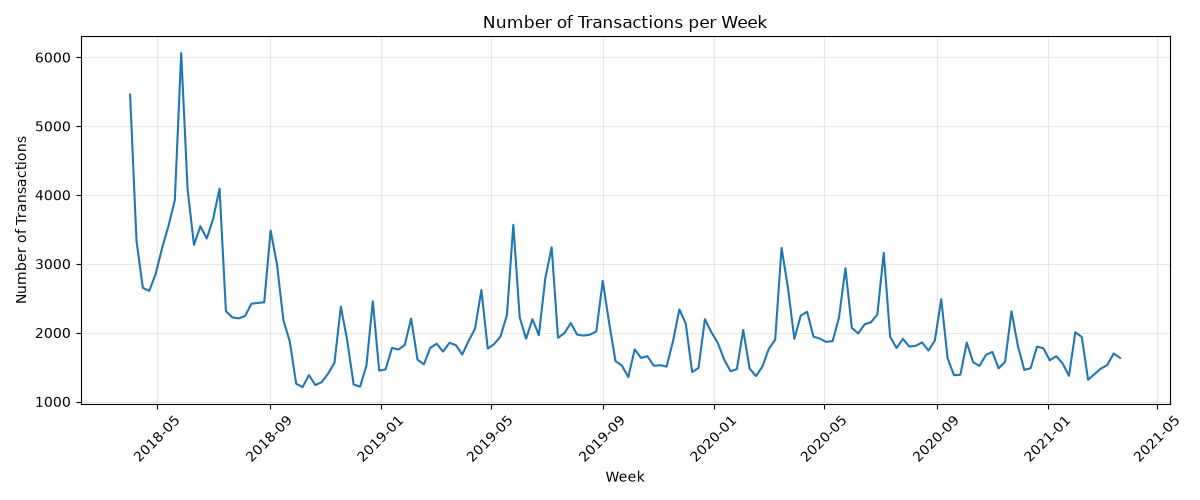

In [15]:
# Examining the transaction activity over time in weekly basis
df["date"] = pd.to_datetime(df["date"])

# Count transactions per week
weekly_transactions = (
    df
    .set_index("date")
    .resample("W-SUN") # weekly level - ends on Sunday
    .size()
)

# Plot
plt.figure(figsize=(12, 5))
plt.plot(weekly_transactions.index, weekly_transactions.values)

plt.title("Number of Transactions per Week")
plt.xlabel("Week")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# Number of total transactions and unique customers
df.shape[0], df['cust'].nunique()

(323615, 50000)

A little quick math may lead us to estimate that, on average, each customer is responsible for about 6.5 transactions, but this would not provide an accurate representation of customer activity.
Instead, if we count the unique transactions by customer and then examine the frequency of these values, we see that approximately the 20% of the customers have made only one transaction.

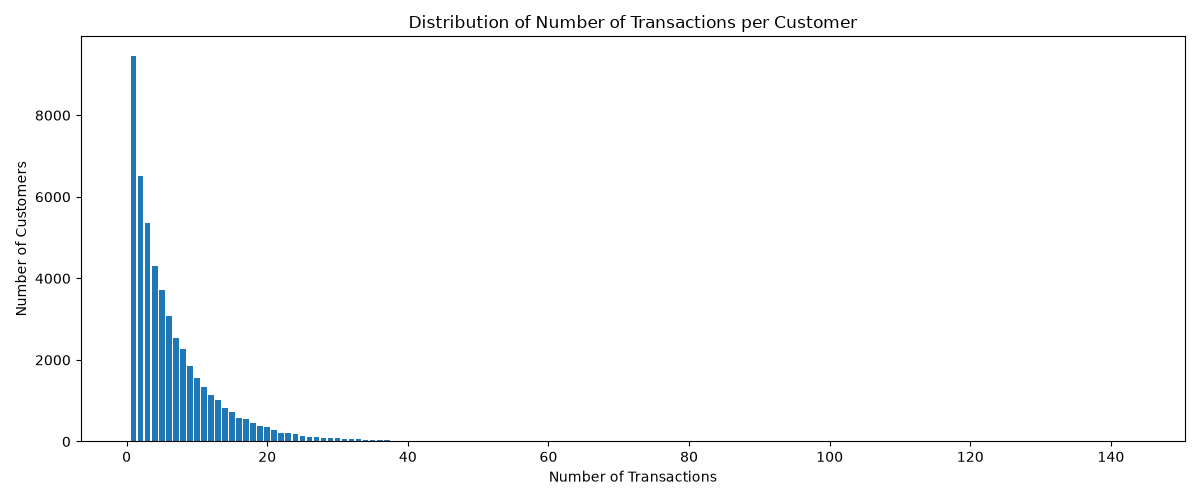

In [17]:
import matplotlib.pyplot as plt
import mplcursors

transactions_per_customer = (
    df.groupby("cust")
      .size()
)

transaction_frequency = (
    transactions_per_customer
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    transaction_frequency.index,
    transaction_frequency.values
)

ax.set_title("Distribution of Number of Transactions per Customer")
ax.set_xlabel("Number of Transactions")
ax.set_ylabel("Number of Customers")

cursor = mplcursors.cursor(bars, hover=True)

@cursor.connect("add")
def on_add(sel):
    bar = sel.artist[sel.index]

    transactions = int(bar.get_x() + bar.get_width() / 2)
    customers = int(bar.get_height())

    sel.annotation.set_text(
        f"Transactions: {transactions}\n"
        f"Customers: {customers:,}"
    )

plt.tight_layout()
plt.show()

Focusing on customers with repeat purchases, we can examine the distribution of the days between purchase events. What's important to note here is that most customers buy the product on average within **5 to 15** weeks of a prior purchase. Longer gaps do occur but significantly fewer customers have longer gaps between purchases.

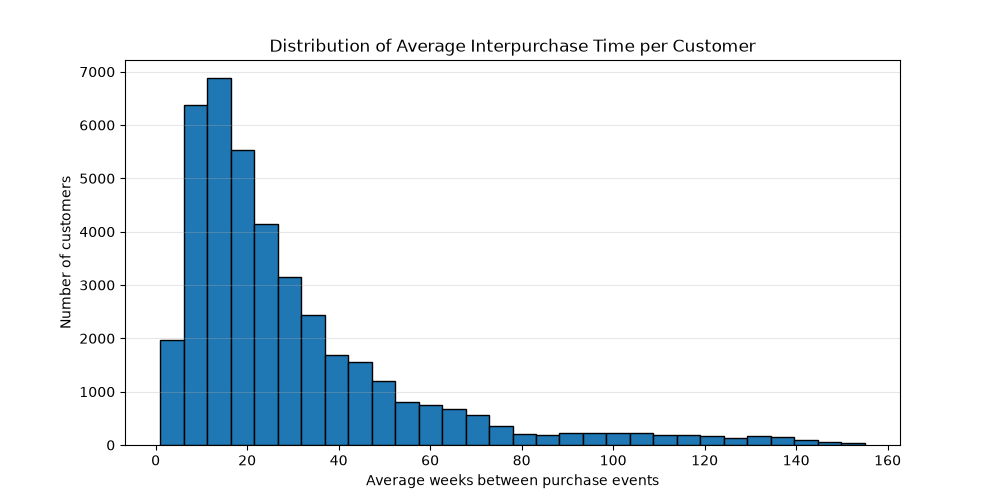

In [18]:
# Sort purchases by customer and week
df = df.sort_values(["cust", "iri_week"])

# Calculate weeks between consecutive purchase events
df["weeks_between"] = (
    df.groupby("cust")["iri_week"]
      .diff()
)

# Customer-level average weeks between purchases
customer_avg_gap = (
    df.groupby("cust")["weeks_between"]
      .mean()
      .dropna()
      .reset_index(name="avg_weeks_between")
)

plt.figure(figsize=(10, 5))

plt.hist(
    customer_avg_gap["avg_weeks_between"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Average weeks between purchase events")
plt.ylabel("Number of customers")
plt.title("Distribution of Average Interpurchase Time per Customer")

plt.grid(axis="y", alpha=0.3)
plt.show()


### **Step 2: Split the time into calibration and holdout period**
Given the period starts on 2018-04-01, use the first 104 weeks for calibration and the following 52 weeks for holdout.


In [19]:
observation_start = df["date"].min()

calibration_end = observation_start + pd.Timedelta(weeks=103)
holdout_start = calibration_end + pd.Timedelta(weeks=1)
holdout_end = df["date"].max()

print("Calibration:")
print(observation_start, "→", calibration_end)

print("\nHoldout:")
print(holdout_start, "→", holdout_end)

Calibration:
2018-04-01 00:00:00 → 2020-03-22 00:00:00

Holdout:
2020-03-29 00:00:00 → 2021-03-21 00:00:00


In [20]:
calibration_tx = df[
    df["date"] <= calibration_end
].copy()

holdout_tx = df[
    df["date"] >= holdout_start
].copy()

### **Step 3: Calculate Customer Metrics for Callibration and Holdout Sets**

Customer behaviour is summarized using three key variables:

* **Frequency** – number of repeat purchases
* **Recency** – time between the first and most recent purchase
* **Age(T)** – time between the first purchase and the end of the observation period

In [21]:
def create_rfm(data, observation_end):

    customer_data = (
        data.groupby("cust")
            .agg(
                first_purchase=("date", "min"),
                last_purchase=("date", "max"),
                purchase_weeks=("date", "nunique"),
                monetary=("spend", "mean")
            )
    )

    customer_data["frequency"] = (
        customer_data["purchase_weeks"] - 1
    )

    customer_data["recency"] = (
        (customer_data["last_purchase"] -
         customer_data["first_purchase"])
        .dt.days / 7
    ).astype(int)

    customer_data["Age(T)"] = (
        (observation_end -
         customer_data["first_purchase"])
        .dt.days / 7
    ).astype(int)

    return customer_data[
        ["frequency", "recency", "Age(T)", "monetary"]
    ]

In [22]:
calibration_data = create_rfm(
    calibration_tx,
    calibration_end
)

calibration_data.head()

,frequency,recency,Age(T),monetary
cust,,,,
1000246458,5,89,89,3.625
1000251782,2,55,85,3.490
1000252771,0,0,98,6.490
1000257574,1,81,97,3.990
1000264172,2,65,81,3.490


For validation, count how many purchase weeks each existing customer actually generated during the following year

In [23]:
holdout_actual = (
    holdout_tx.groupby("cust")
                 .agg(
                     purchases_holdout=("date", "nunique"),
                     revenue_holdout=("spend", "sum"),
                     avg_spend_holdout=("spend", "mean")
                 )
)

## 4. Model Performance and Validation

### **BG/NBD Model – Intuition**

The **BG/NBD (Beta-Geometric / Negative Binomial Distribution)** model is a probabilistic model used to predict future purchases in **non-contractual settings**, where we do not directly know when a customer has stopped buying.

A simple way to think about the model is that every customer has two underlying behaviours:

- **Purchase behaviour:** while the customer is active, they purchase at their own individual rate.
- **Dropout behaviour:** after each purchase, there is some probability that the customer becomes inactive and never purchases again.

The model assumes that these behaviours vary across customers<sup>2</sup>:

- Purchase rates differ across customers and are modeled with a **Gamma distribution**.

![Purchase Process](./images/transaction_process.jpg)

- Dropout probabilities differ across customers and are modeled with a **Beta distribution**.

![Dropout Process](./images/dropout_process.jpg)

Using only three pieces of customer history:

- **Frequency** – number of repeat purchase occasions
- **Recency** – time between the first and most recent purchase
- **T** – time between the first purchase and the end of the observation period

the BG/NBD model estimates:

1. the probability that a customer is still active;
2. the expected number of future purchases.

In this analysis, the model is fitted on the **104-week calibration period** and later evaluated on the **52-week holdout period**.

### **Step 1: Fitting the model**

In [25]:
bgnbd_model = BetaGeoFitter(penalizer_coef=0.001)

bgnbd_model.fit(
    calibration_data["frequency"],
    calibration_data["recency"],
    calibration_data["Age(T)"]
)

bgnbd_model.summary


,coef,se(coef),lower 95% bound,upper 95% bound
r,0.866001,0.007518,0.851266,0.880737
alpha,22.796214,0.237950,22.329831,23.262597
a,0.007167,0.001120,0.004972,0.009363
b,0.531419,0.065822,0.402409,0.660429


### Interpretaton of transaction process

The first two parameters, **r and alpha**, govern the heterogeneity in customers' purchase rates and look numerically well behaved. The standard errors are small and the confidence intervals are well defined, which is a good sign.
The **r/alpha** rate is **0.866/22.79** gives **0.038 repeat purchases per week**, **1.97 per year on average accross customers**. That level is plausible for a product/category where many customers purchase infrequently, especially given that a large share of customers have no repeat transactions in calibration.
Also, because r < 1, the Gamma distribution of purchase rates is quite right-skewed. In practical terms, that means the model is capturing a population with many **low-frequency customers and a smaller number of much more active customers**. That seems consistent with the frequency distribution i showed earlier.

### Interpretaton of dropout process

The issue is with a and b, which govern the Beta distribution for the probability that a customer becomes inactive after a transaction. The mean dropout probability implied by these parameters is approximately **a/(a+b) ~ 0**. This indicates that accordingly the model there is no clear evidence that customers are permanently dropping out during the calibration period. So, given the following diagnostics we wxpect to see that a large concentration of probabilities close to 1.

In [26]:
calibration_data["prob_alive"] = (
    bgnbd_model.conditional_probability_alive(
        calibration_data["frequency"],
        calibration_data["recency"],
        calibration_data["Age(T)"]
    )
)

calibration_data["prob_alive"].describe().round(2)

count    50000.00
mean         0.98
std          0.04
min          0.00
25%          0.99
50%          1.00
75%          1.00
max          1.00
Name: prob_alive, dtype: float64

Around **20% of customers** made no repeat purchase, making it difficult to distinguish between low purchase intensity and customer dropout. At the same time, repeat purchasers often bought relatively recently, providing limited evidence of inactivity. As a result, the dropout parameters are weakly identified.

In [28]:
repeat_customers = calibration_data[
    calibration_data["frequency"] > 0
].copy()

repeat_customers["recency_ratio"] = (
    repeat_customers["recency"] /
    repeat_customers["Age(T)"]
)

repeat_customers["recency_ratio"].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.99]
)

count    37637.000000
mean         0.739847
std          0.259423
min          0.009709
10%          0.329670
25%          0.592233
50%          0.831579
75%          0.953488
99%          1.000000
max          1.000000
Name: recency_ratio, dtype: float64

### **Step 2: Predict & Evaluate**

In [34]:
calibration_data["bgnbd_pred_52w"] = (
    bgnbd_model.conditional_expected_number_of_purchases_up_to_time(
        52, # weeks - 1 year prediction
        calibration_data["frequency"],
        calibration_data["recency"],
        calibration_data["Age(T)"]
    )
)

In [30]:
bgnbd_validation = calibration_data.join(
    holdout_actual[["purchases_holdout"]],
    how="left"
)

bgnbd_validation["purchases_holdout"] = (
    bgnbd_validation["purchases_holdout"]
    .fillna(0)
)

### Customer-Level Prediction Error

The BG/NBD model achieves an **MAE of 1.32 purchases**, meaning that, on average, the predicted number of purchases differs from the actual number by about **1.3 purchases per customer**.

The **RMSE of 1.93 purchases** is higher than the MAE, indicating that while most prediction errors are relatively small, there are some customers for whom the model makes larger errors.

In [31]:
mae = mean_absolute_error(
    bgnbd_validation["purchases_holdout"],
    bgnbd_validation["bgnbd_pred_52w"]
)

rmse = np.sqrt(
    mean_squared_error(
        bgnbd_validation["purchases_holdout"],
        bgnbd_validation["bgnbd_pred_52w"]
    )
)

print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")

MAE: 1.322
RMSE: 1.934


In [32]:
actual = bgnbd_validation["purchases_holdout"].sum()
predicted = bgnbd_validation["bgnbd_pred_52w"].sum()

print(f"Actual:    {actual:.0f}")
print(f"Predicted: {predicted:.0f}")
print(f"Error: {(predicted / actual - 1):.2%}")

Actual:    95800
Predicted: 95865
Error: 0.07%


### Validation by Historical Frequency

- Higher historical purchase frequency is associated with higher future purchase activity.
- BG/NBD closely follows the observed holdout averages for the majority of customers.
- Differences become larger at very high frequency levels, where only a few customers are available.
- Therefore, predictions in the extreme tail are less stable and should be interpreted cautiously.

In [40]:
plot_df = calibration_data[
    ["frequency", "recency", "Age(T)", "monetary", "bgnbd_pred_52w"]
].join(
    holdout_actual[["purchases_holdout"]],
    how="left"
)

plot_df["purchases_holdout"] = plot_df["purchases_holdout"].fillna(0)

freq_plot = (
    plot_df
    .groupby("frequency")
    .agg(
        actual=("purchases_holdout", "mean"),
        predicted=("bgnbd_pred_52w", "mean"),
        customers=("purchases_holdout", "size")
    )
    .reset_index()
)

freq_plot

,frequency,actual,predicted,customers
0,0,0.367953,0.390364,12363
1,1,0.806862,0.793208,8336
2,2,1.258915,1.259747,6562
3,3,1.703464,1.703234,4937
4,4,2.169608,2.140991,3797
...,...,...,...,...
56,58,28.000000,24.297713,1
57,60,29.000000,25.113253,1
58,61,25.000000,25.536193,1
59,67,15.000000,28.007217,1


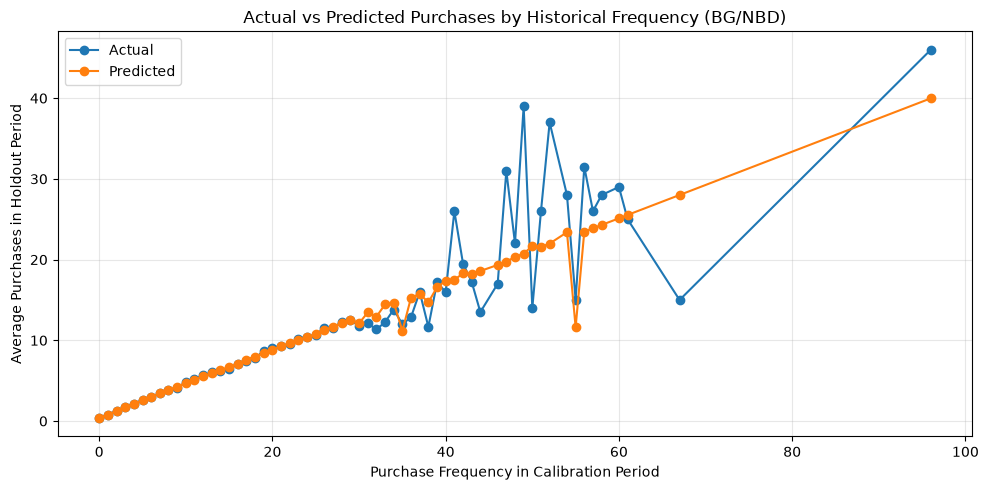

In [166]:
plt.figure(figsize=(10, 5))

plt.plot(
    freq_plot["frequency"],
    freq_plot["actual"],
    marker="o",
    label="Actual"
)

plt.plot(
    freq_plot["frequency"],
    freq_plot["predicted"],
    marker="o",
    label="Predicted"
)

plt.title("Actual vs Predicted Purchases by Historical Frequency (BG/NBD)")
plt.xlabel("Purchase Frequency in Calibration Period")
plt.ylabel("Average Purchases in Holdout Period")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

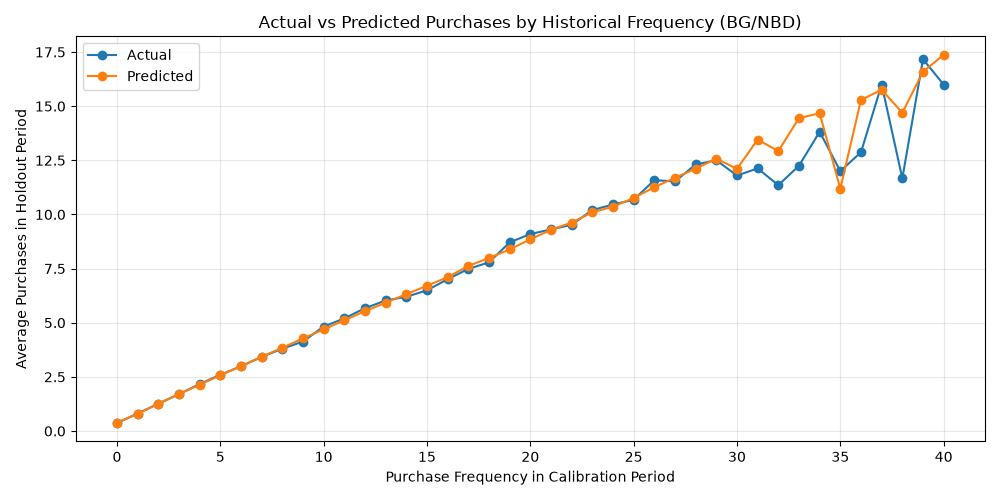

In [41]:
freq_plot_40 = freq_plot[
    freq_plot["frequency"] <= 40
]

plt.figure(figsize=(10, 5))

plt.plot(
    freq_plot_40["frequency"],
    freq_plot_40["actual"],
    marker="o",
    label="Actual"
)

plt.plot(
    freq_plot_40["frequency"],
    freq_plot_40["predicted"],
    marker="o",
    label="Predicted"
)

plt.title("Actual vs Predicted Purchases by Historical Frequency (BG/NBD)")
plt.xlabel("Purchase Frequency in Calibration Period")
plt.ylabel("Average Purchases in Holdout Period")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Validation by Time Since Last Purchase

- Customers who purchased recently are substantially more active in the holdout period.
- Future purchase activity decreases as the time since the last purchase increases.
- BG/NBD closely follows this observed pattern across the full range.
- This suggests that the model captures the relationship between recency and future purchasing behavior well.

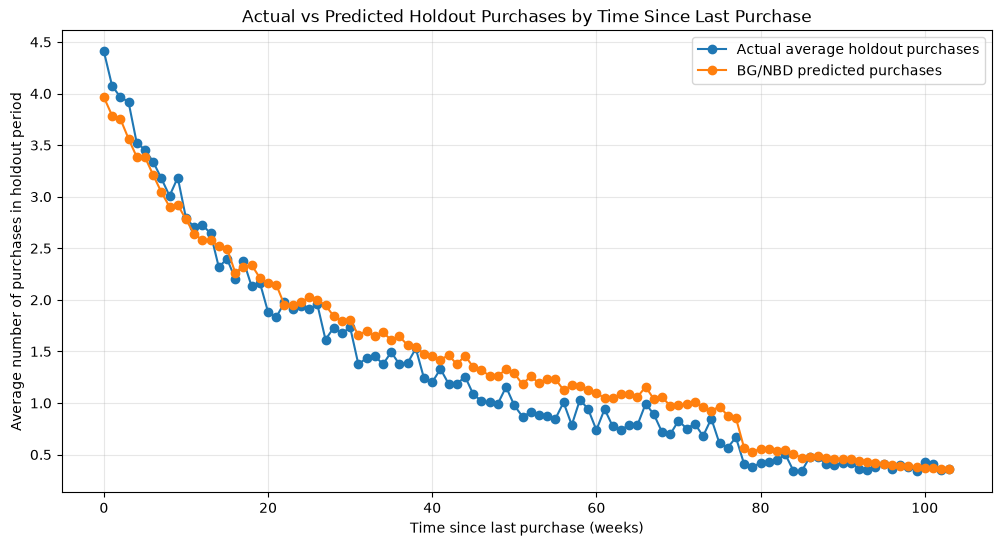

In [172]:
# Create time since last purchase
bgnbd_validation["time_since_last_purchase"] = (
    bgnbd_validation["Age(T)"] - bgnbd_validation["recency"]
)

# Aggregate mean actual and predicted purchases by time since last purchase
plot_df = (
    bgnbd_validation
    .groupby("time_since_last_purchase")[["purchases_holdout", "bgnbd_pred_52w"]]
    .mean()
    .reset_index()
    .sort_values("time_since_last_purchase")
)

# Plot
plt.figure(figsize=(12, 6))

plt.plot(
    plot_df["time_since_last_purchase"],
    plot_df["purchases_holdout"],
    marker="o",
    label="Actual average holdout purchases"
)

plt.plot(
    plot_df["time_since_last_purchase"],
    plot_df["bgnbd_pred_52w"],
    marker="o",
    label="BG/NBD predicted purchases"
)

plt.xlabel("Time since last purchase (weeks)")
plt.ylabel("Average number of purchases in holdout period")
plt.title("Actual vs Predicted Holdout Purchases by Time Since Last Purchase")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Customer Lifetime Value Estimation

After predicting the expected number of transactions over the next 52 weeks, we can translate purchase activity into an estimate of **future customer value**.

For this analysis, CLV is approximated as:

**CLV = Predicted Transactions × Average Monetary Value**

where:

- **Predicted Transactions** are estimated by the BG/NBD model for the next 52 weeks.
- **Monetary Value** represents the customer's average spend per purchase.

In this dataset, monetary value is largely driven by the price of the product and therefore shows relatively limited variation across customers.

As a result, differences in estimated CLV are mainly driven by differences in **expected future purchase frequency**.

This makes the BG/NBD transaction prediction especially important: customers who are expected to purchase more frequently will also generate higher expected future value.

In [48]:
bgnbd_validation["CLV_52w"] = (
    bgnbd_validation["bgnbd_pred_52w"] *
    bgnbd_validation["monetary"]
)

bgnbd_validation["CLV_52w"].describe().round(2)

count    50000.00
mean         7.99
std          8.96
min          0.00
25%          2.44
50%          5.22
75%         10.52
max        592.48
Name: CLV_52w, dtype: float64

## 5. Customer Engagement Segmentation

#### Clustering Approach

K-Means clustering was applied to the **log-transformed predicted number of purchases** for the next 52 weeks.

The logarithmic transformation reduces the influence of a small number of customers with very high predicted activity, allowing the clustering to better separate the broader customer population.

The three resulting clusters were ordered according to their average predicted purchase activity and labelled as **Poor, Medium, and High Engagement**.

In [44]:
segment_data = bgnbd_validation[
    bgnbd_validation["bgnbd_pred_52w"].notna()
].copy()

segment_data["log_pred_52w"] = np.log1p(
    segment_data["bgnbd_pred_52w"]
)

X = segment_data[["log_pred_52w"]]

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

segment_data["cluster"] = kmeans.fit_predict(X)

cluster_order = (
    segment_data
    .groupby("cluster")["bgnbd_pred_52w"]
    .mean()
    .sort_values()
    .index
)

cluster_labels = {
    cluster_order[0]: "Poor engagement",
    cluster_order[1]: "Medium engagement",
    cluster_order[2]: "High engagement"
}

segment_data["time_since_last_purchase"] = (
    segment_data["Age(T)"] -
    segment_data["recency"]
)

segment_data["engagement_segment"] = (
    segment_data["cluster"]
    .map(cluster_labels)
)

In [46]:
segment_profile = (
    segment_data
    .groupby("engagement_segment")
    .agg(
        customers=("bgnbd_pred_52w", "size"),
        avg_predicted_purchases=("bgnbd_pred_52w", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_recency=("recency", "mean"),
        avg_T=("Age(T)", "mean"),
        avg_time_since_last_purchase=("time_since_last_purchase", "mean"),
        avg_prob_alive=("prob_alive", "mean"),
        avg_monetary=("monetary", "mean"),
        avg_actual_holdout=("purchases_holdout", "mean")
    )
    .reindex([
        "Poor engagement",
        "Medium engagement",
        "High engagement"
    ])
)

segment_profile.round(2)

,customers,avg_predicted_purchases,avg_frequency,avg_recency,avg_T,avg_time_since_last_purchase,avg_prob_alive,avg_monetary,avg_actual_holdout
engagement_segment,,,,,,,,,
Poor engagement,20884,0.56,0.43,18.18,92.70,74.52,0.97,4.12,0.55
Medium engagement,19280,1.85,3.36,72.09,94.35,22.26,0.99,4.15,1.86
High engagement,9836,4.94,10.57,88.65,96.38,7.73,1.00,4.19,4.94


The medium segment is especially interesting because it contains about 40% of the customers. They are already engaged, but there is still room to move them toward the high-engagement group. Their average time since last purchase is around 22 weeks, which gives us a useful starting point for when a re-engagement campaign could be tested.

## 6. Moving to Production

For each new client case or brand, the modeling process can be treated as a standardized experiment rather than relying on one fixed model configuration.

The main settings to test are:

- **Model selection:** BG/NBD, Pareto/NBD, BG/BB, or other suitable BTYD alternatives
- **Penalizer coefficient:** values between **0.001 and 0.1**
- **Prediction horizon:** defined according to the business use case, for example 13, 26, 52, 104 weeks

Each model configuration is fitted on the calibration period and evaluated on the holdout period using the same validation metrics:

- **MAE**
- **RMSE**
- **Aggregate Error %**

The results are summarized in a benchmark table, allowing the different model and penalizer combinations to be compared consistently.

The final production version is selected based on the best overall balance between customer-level prediction accuracy, aggregate prediction accuracy, parameter stability, and business interpretability.

This creates a repeatable framework that can be applied independently to each brand, since purchasing behavior and customer dynamics may differ substantially across categories.

## 7. Conclusions

This analysis extends short-term campaign measurement into a longer-term customer perspective by estimating **future purchasing activity and customer engagement**.

The BG/NBD model was able to capture the main behavioral patterns in the data:

- Customers with higher historical purchase frequency tend to remain more active in the future.
- Customers who purchased more recently are also more likely to generate future transactions.
- For the majority of the customer population, predicted purchases follow the observed holdout behavior closely.
- Prediction uncertainty increases mainly for extremely high-frequency customers, where only a very small number of observations are available.

The analysis supports the two objectives introduced at the beginning of the case.

First, the customer-level predictions and engagement segmentation provide a richer view of the audience beyond the short-term campaign response. By identifying **Poor, Medium, and High Engagement** customers, the client can better understand which households have stronger future purchase potential and use this information to improve campaign targeting and re-engagement strategies.

Second, the same framework could be integrated with the existing **incremental lift methodology**. Instead of evaluating exposed and control households only over the initial 2–4 week campaign window, future purchase activity could also be modeled for both groups over longer horizons such as **26 or 52 weeks**.

The estimated purchase propensity or expected future activity could also be included as an additional matching factor when constructing comparable exposed and control groups. This would help ensure that households are not only similar based on historical characteristics, but also on their underlying likelihood of future purchasing.

The long-term incremental impact could then be estimated as the difference in future value between the matched exposed and control populations:

**Long-Term Incremental Value = Future Value of Exposed Group − Future Value of Matched Control Group**

Overall, the approach can help clients move beyond asking only **“Did the campaign generate incremental lift?”** toward also understanding:

- **“Did the campaign generate incremental sales in the short term?”**
- **Which customers are likely to remain engaged?**
- **Which customers should be prioritized for future targeting?**
- **When might a re-engagement action be most relevant?**

## 8. Limitations

The BG/NBD approach provides a strong and interpretable framework for estimating future purchase activity, but there are some important limitations to consider.

- **P(alive) should not be interpreted as a direct churn probability.**  
  In a non-contractual setting, churn is not explicitly observed. A customer who has not purchased for a long period may still return in the future, so `P(alive)` should be treated as a model-based behavioral indicator rather than a literal probability of churn.

- **Predictions are less stable for extreme customer behavior.**  
  At very high purchase frequencies, the number of available customers becomes very small, making the observed averages more volatile and the model predictions less reliable.

- **BTYD models use a relatively limited set of behavioral information.**  
  This is also one of their strengths: they are **fast, interpretable, computationally efficient, and work well even when individual customer histories are sparse**. Rather than fitting each customer independently, they estimate behavior within a common probabilistic framework based mainly on frequency, recency, and customer age.

However, there may be client cases where richer customer information is available or required, such as:

- demographics
- promotion and campaign exposure
- channel behavior
- loyalty information
- recent purchasing trends
- average interpurchase time

In these situations, machine-learning approaches such as **XGBoost** or **Random Forest** could be evaluated as complementary alternatives, since they can incorporate a wider range of features and capture more complex and nonlinear relationships.

# References
1. https://www.brucehardie.com/papers/020/fader_et_al_mksc_10.pdf
2. https://medium.com/data-science/predicting-customer-lifetime-value-with-buy-til-you-die-probabilistic-models-in-python-f5cac78758d9
